<a href="https://colab.research.google.com/github/kagermanov98/community-life-lab/blob/main/01_population_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np

# Community Life Lab - Initial settings
PROJECT_NAME = "Community Life Lab"
VERSION = "0.1.0"
POPULATION_SIZE = 1500
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Create a small test population
people = pd.DataFrame({
    "Person_ID": [f"Person_{i:04d}" for i in range(1, 11)],
    "Age": rng.integers(18, 65, size=10),
    "House_ID": [f"House_{i:03d}" for i in range(1, 11)]
})

print(f"Project: {PROJECT_NAME}")
print(f"Version: {VERSION}")
print("First 10 fictional people:")

display(people)


Project: Community Life Lab
Version: 0.1.0
First 10 fictional people:


,Person_ID,Age,House_ID
0,Person_0001,22,House_001
1,Person_0002,54,House_002
2,Person_0003,48,House_003
3,Person_0004,38,House_004
4,Person_0005,38,House_005
5,Person_0006,58,House_006
6,Person_0007,22,House_007
7,Person_0008,50,House_008
8,Person_0009,27,House_009
9,Person_0010,22,House_010


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

N_PEOPLE = 10_000
N_HOUSES = 3_500

housing_types = {
    "studio": {
        "bedrooms": 0, "living_rooms": 1,
        "bathrooms": 1, "capacity": 1
    },
    "1+1": {
        "bedrooms": 1, "living_rooms": 1,
        "bathrooms": 1, "capacity": 2
    },
    "2+1": {
        "bedrooms": 2, "living_rooms": 1,
        "bathrooms": 1, "capacity": 4
    },
    "3+1": {
        "bedrooms": 3, "living_rooms": 1,
        "bathrooms": 2, "capacity": 5
    },
    "4+1": {
        "bedrooms": 4, "living_rooms": 1,
        "bathrooms": 2, "capacity": 7
    },
    "5+1": {
        "bedrooms": 5, "living_rooms": 1,
        "bathrooms": 3, "capacity": 9
    },
    "5+2": {
        "bedrooms": 5, "living_rooms": 2,
        "bathrooms": 3, "capacity": 10
    },
    "two_floor": {
        "bedrooms": 4, "living_rooms": 1,
        "bathrooms": 3, "capacity": 7
    }
}

print("Housing types:", len(housing_types))
print("Target population:", N_PEOPLE)
print("Target houses:", N_HOUSES)


Housing types: 8
Target population: 10000
Target houses: 3500


In [3]:

housing_counts = {
    "studio": 250,
    "1+1": 750,
    "2+1": 1000,
    "3+1": 800,
    "4+1": 400,
    "5+1": 150,
    "5+2": 50,
    "two_floor": 100
}

house_type_list = []

for house_type, count in housing_counts.items():
    house_type_list.extend([house_type] * count)

assert len(house_type_list) == N_HOUSES

rng.shuffle(house_type_list)

# Keep the important original households
house_type_list[10] = "3+1"       # House_011
house_type_list[13] = "two_floor" # House_014
house_type_list[14] = "2+1"       # House_015

house_rows = []

for i, house_type in enumerate(house_type_list, start=1):
    details = housing_types[house_type]

    house_rows.append({
        "House_ID": f"House_{i:04d}",
        "House_Type": house_type,
        "Bedrooms": details["bedrooms"],
        "Living_Rooms": details["living_rooms"],
        "Bathrooms": details["bathrooms"],
        "Max_Residents": details["capacity"]
    })

houses_df = pd.DataFrame(house_rows)

display(houses_df.head())
print("Houses created:", len(houses_df))


,House_ID,House_Type,Bedrooms,Living_Rooms,Bathrooms,Max_Residents
0,House_0001,1+1,1,1,1,2
1,House_0002,2+1,2,1,1,4
2,House_0003,4+1,4,1,2,7
3,House_0004,2+1,2,1,1,4
4,House_0005,1+1,1,1,1,2


Houses created: 3500


In [4]:

# Reserve the established households.
# House_0011 has five family members.
# House_0014 has three family members.
# House_0015 has Person_03.

fixed_members = {
    "House_0011": [
        "Person_0018", "Person_0019",
        "Person_0020", "Person_0021", "Person_0022"
    ],
    "House_0014": [
        "Person_0001", "Person_0002", "Person_0024"
    ],
    "House_0015": ["Person_0003"]
}

houses_df["Residents"] = 1

for house_id, members in fixed_members.items():
    mask = houses_df["House_ID"] == house_id
    houses_df.loc[mask, "Residents"] = len(members)

# Check that reserved families fit.
assert (
    houses_df["Residents"] <= houses_df["Max_Residents"]
).all(), "A reserved household exceeds its capacity"

remaining = N_PEOPLE - int(houses_df["Residents"].sum())

# Randomly distribute residents into available spaces.
# The probability of selection is weighted by remaining capacity.
while remaining > 0:
    eligible = houses_df[
        (houses_df["Residents"] < houses_df["Max_Residents"])
        & (~houses_df["House_ID"].isin(fixed_members))
    ]

    if eligible.empty:
        raise ValueError("Not enough housing capacity")

    available_spaces = (
        eligible["Max_Residents"] - eligible["Residents"]
    )

    probabilities = available_spaces / available_spaces.sum()

    chosen_index = rng.choice(
        eligible.index.to_numpy(),
        p=probabilities.to_numpy()
    )

    houses_df.at[chosen_index, "Residents"] += 1
    remaining -= 1

assert houses_df["Residents"].sum() == N_PEOPLE

print("Total population:", houses_df["Residents"].sum())
print("Total houses:", len(houses_df))
print("Average residents:", round(houses_df["Residents"].mean(), 2))


Total population: 10000
Total houses: 3500
Average residents: 2.86


In [5]:

person_ids = [
    f"Person_{i:04d}"
    for i in range(1, N_PEOPLE + 1)
]

reserved_people = {
    person
    for members in fixed_members.values()
    for person in members
}

available_people = [
    person for person in person_ids
    if person not in reserved_people
]

rng.shuffle(available_people)

membership_rows = []
cursor = 0

for house in houses_df.itertuples(index=False):
    if house.House_ID in fixed_members:
        members = fixed_members[house.House_ID]
    else:
        members = available_people[
            cursor:cursor + house.Residents
        ]
        cursor += house.Residents

    for person in members:
        membership_rows.append({
            "Person_ID": person,
            "House_ID": house.House_ID
        })

membership_df = pd.DataFrame(membership_rows)

assert len(membership_df) == N_PEOPLE
assert membership_df["Person_ID"].is_unique

display(membership_df.head())


,Person_ID,House_ID
0,Person_5584,House_0001
1,Person_3899,House_0002
2,Person_6922,House_0002
3,Person_8729,House_0003
4,Person_4417,House_0003


In [6]:

fixed_profiles = {
    "Person_0001": (42, "male", "parent"),
    "Person_0002": (40, "female", "parent"),
    "Person_0024": (14, "male", "child"),
    "Person_0018": (38, "female", "parent"),
    "Person_0019": (40, "male", "parent"),
    "Person_0020": (16, "male", "child"),
    "Person_0021": (12, "male", "child"),
    "Person_0022": (9, "female", "child")
}

people_rows = []
relationship_rows = []

def add_relationship(person_a, person_b, kind):
    relationship_rows.append({
        "Person_ID": person_a,
        "Related_Person_ID": person_b,
        "Relationship": kind
    })

for house_id, group in membership_df.groupby("House_ID"):
    members = group["Person_ID"].tolist()
    n = len(members)

    if house_id in fixed_members:
        structure = "specified"
    elif n == 1:
        structure = "single"
    else:
        structure = str(rng.choice(
            ["family", "roommates", "siblings"],
            p=[0.60, 0.30, 0.10]
        ))

    for index, person in enumerate(members):
        if person in fixed_profiles:
            age, sex, role = fixed_profiles[person]
        elif structure == "family" and index >= 2:
            age = int(rng.integers(1, 19))
            sex = str(rng.choice(["male", "female"]))
            role = "child"
        else:
            age = int(rng.integers(22, 66))
            sex = str(rng.choice(["male", "female"]))
            role = "parent" if structure == "family" else "adult"

        people_rows.append({
            "Person_ID": person,
            "House_ID": house_id,
            "Age": age,
            "Sex": sex,
            "Household_Role": role,
            "Household_Structure": structure
        })

    if house_id in fixed_members:
        continue

    if structure == "family":
        parent_ids = members[:2]
        child_ids = members[2:]

        add_relationship(parent_ids[0], parent_ids[1], "partner")
        add_relationship(parent_ids[1], parent_ids[0], "partner")

        for parent in parent_ids:
            for child in child_ids:
                add_relationship(parent, child, "parent_of")
                add_relationship(child, parent, "child_of")

    elif structure in ["siblings", "roommates"]:
        for i, a in enumerate(members):
            for b in members[i + 1:]:
                add_relationship(a, b, structure[:-1])
                add_relationship(b, a, structure[:-1])

# Preserve the established fictional families
for a, b in [
    ("Person_0001", "Person_0002"),
    ("Person_0018", "Person_0019")
]:
    add_relationship(a, b, "spouse")
    add_relationship(b, a, "spouse")

for parent in ["Person_0001", "Person_0002"]:
    add_relationship(parent, "Person_0024", "parent_of")
    add_relationship("Person_0024", parent, "child_of")

for parent in ["Person_0018", "Person_0019"]:
    for child in ["Person_0020", "Person_0021", "Person_0022"]:
        add_relationship(parent, child, "parent_of")
        add_relationship(child, parent, "child_of")

add_relationship("Person_0001", "Person_0018", "sibling")
add_relationship("Person_0018", "Person_0001", "sibling")

people_df = pd.DataFrame(people_rows)
relationships_df = pd.DataFrame(relationship_rows)

print("People generated:", len(people_df))
print("Relationship records:", len(relationships_df))
display(people_df.head(10))


People generated: 10000
Relationship records: 23040


,Person_ID,House_ID,Age,Sex,Household_Role,Household_Structure
0,Person_5584,House_0001,64,male,adult,single
1,Person_3899,House_0002,31,female,parent,family
2,Person_6922,House_0002,30,male,parent,family
3,Person_8729,House_0003,52,male,parent,family
4,Person_4417,House_0003,40,female,parent,family
5,Person_5132,House_0003,16,female,child,family
6,Person_4429,House_0003,14,male,child,family
7,Person_5102,House_0004,44,female,parent,family
8,Person_2196,House_0004,64,male,parent,family
9,Person_3467,House_0004,18,female,child,family


In [7]:

# Population checks
assert len(people_df) == N_PEOPLE
assert people_df["Person_ID"].is_unique
assert people_df["House_ID"].isin(houses_df["House_ID"]).all()

# Household occupancy checks
actual = people_df.groupby("House_ID").size()
expected = houses_df.set_index("House_ID")["Residents"]

assert actual.sort_index().equals(expected.sort_index())
assert (
    houses_df["Residents"] <= houses_df["Max_Residents"]
).all()

# Relationship checks
assert relationships_df["Person_ID"].isin(
    people_df["Person_ID"]
).all()

assert relationships_df["Related_Person_ID"].isin(
    people_df["Person_ID"]
).all()

# Preserve original characters
profiles = people_df.set_index("Person_ID")

assert profiles.loc["Person_0001", "Age"] == 42
assert profiles.loc["Person_0024", "Age"] == 14
assert profiles.loc["Person_0001", "House_ID"] == "House_0014"
assert profiles.loc["Person_0018", "House_ID"] == "House_0011"

print("All validation tests passed!")
print(f"Population: {len(people_df):,}")
print(f"Houses: {len(houses_df):,}")
print(f"Relationships: {len(relationships_df):,}")


All validation tests passed!
Population: 10,000
Houses: 3,500
Relationships: 23,040


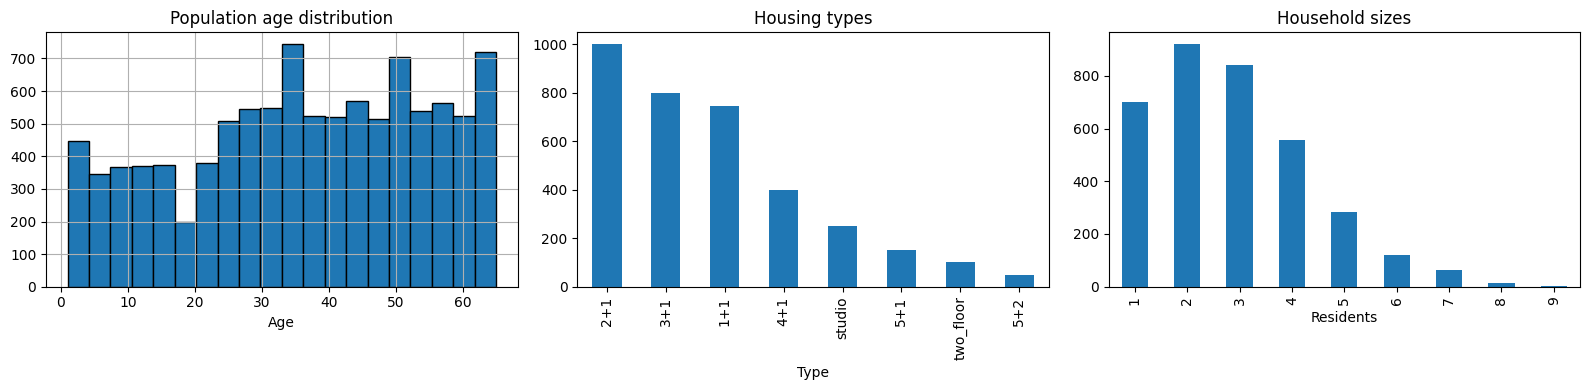

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

people_df["Age"].hist(
    bins=20, ax=axes[0], edgecolor="black"
)
axes[0].set_title("Population age distribution")
axes[0].set_xlabel("Age")

houses_df["House_Type"].value_counts().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Housing types")
axes[1].set_xlabel("Type")

houses_df["Residents"].value_counts().sort_index().plot(
    kind="bar", ax=axes[2]
)
axes[2].set_title("Household sizes")
axes[2].set_xlabel("Residents")

plt.tight_layout()
plt.show()


In [9]:

people_df.to_csv("people.csv", index=False)
houses_df.to_csv("houses.csv", index=False)
relationships_df.to_csv(
    "relationships.csv", index=False
)

print("CSV files created successfully.")


CSV files created successfully.
